# EDA датасетов проверки EvolveAgent

Здесь анализируются данные для проверки предложенных улучшений FEDOT. Это не обучающая выборка Scout и не полный прогон AutoML. Для 32 задач OpenML используются опубликованные показатели качества, восемь рядов читаются из локального FEDOT checkout с проверкой SHA-256. Сырые таблицы и официальные разбиения прочитаны для всех 32 задач OpenML; две задачи дополнительно показаны на отдельных графиках.

Запускайте ячейки сверху вниз из каталога этого ноутбука. Перед запуском задайте `FEDOT_CHECKOUT` — путь к локальному FEDOT. Понадобятся `pandas`, `numpy`, `matplotlib`, `openml` и доступ к OpenML или его кэшу. Ячейки пересоздают сводные CSV и графики в `eda_assets/`; исходные строки в репозиторий не записываются.


In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openml
import pandas as pd

HERE = Path.cwd()
ASSETS = HERE / "eda_assets"
FEDOT = Path(os.environ["FEDOT_CHECKOUT"])
registry = json.loads((HERE / "../evaluation/quality_registry.json").resolve().read_text())
metadata = json.loads((ASSETS / "openml_qualities.json").read_text())
qualities_by_id = {int(row["openml_data"]): row["qualities"] for row in metadata["datasets"]}

def number(value):
    try:
        return float(value) if value is not None else np.nan
    except (TypeError, ValueError):
        return np.nan

inventory = []
for task in registry["datasets"]:
    row = dict(task_id=task["task_id"], name=task["name"], problem=task["problem"],
               source=task["source"], metric=task["metric"], rows=np.nan,
               columns_reported=np.nan, missing_values=np.nan, missing_percent=np.nan,
               minority_percent=np.nan, forecast_horizon=np.nan, checksum_ok="",
               metadata_source="")
    if task["source"] == "openml_task":
        q = qualities_by_id[int(task["openml_data"])]
        for column, quality in [("rows", "NumberOfInstances"),
                                ("columns_reported", "NumberOfFeatures"),
                                ("missing_values", "NumberOfMissingValues"),
                                ("missing_percent", "PercentageOfMissingValues")]:
            row[column] = number(q.get(quality))
        minority = number(q.get("MinorityClassSize"))
        if pd.notna(minority) and row["rows"] > 0:
            row["minority_percent"] = 100 * minority / row["rows"]
        row["metadata_source"] = f"https://www.openml.org/d/{task['openml_data']}"
    else:
        path = (FEDOT / "examples/data/ts" / f"{task['ts_dataset']}.csv"
                if task["source"] == "fedot_public_ts"
                else FEDOT / "examples/real_cases/data" / task["data_path"])
        assert hashlib.sha256(path.read_bytes()).hexdigest() == task["data_sha256"]
        frame = pd.read_csv(path)
        values = pd.to_numeric(frame[task.get("target") or "value"], errors="coerce")
        row.update(rows=len(frame), columns_reported=len(frame.columns),
                   missing_values=int(values.isna().sum()),
                   missing_percent=100 * values.isna().mean(),
                   forecast_horizon=task["forecast_horizon"], checksum_ok="yes",
                   metadata_source=str(path.relative_to(FEDOT)))
    inventory.append(row)

items = pd.DataFrame(inventory)
items.to_csv(ASSETS / "task_inventory.csv", index=False)
print("Задач:", len(items))
display(items.groupby(["problem", "source"]).size().rename("count").to_frame())


Задач: 40


count
problem        source                
classification openml_task         24
regression     openml_task          8
ts_forecasting fedot_local_ts       5
               fedot_public_ts      3

## Состав и объём

В реестре задачи классификации, регрессии и прогнозирования. Для OpenML показаны размеры исходных таблиц по опубликованным метаданным. Число столбцов не равно гарантированно числу признаков после удаления цели и подготовки.

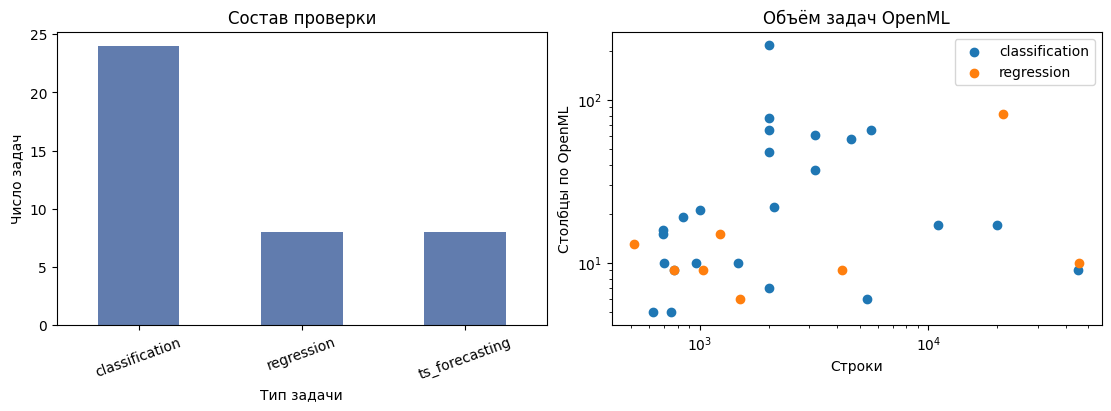

Строки OpenML: 517 — 45730
Столбцы OpenML: 5 — 217


In [2]:
tabular = items[items.source == "openml_task"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
items.problem.value_counts().reindex(["classification", "regression", "ts_forecasting"]).plot.bar(ax=axes[0], color="#617cae")
axes[0].set(title="Состав проверки", ylabel="Число задач", xlabel="Тип задачи")
axes[0].tick_params(axis="x", rotation=20)
for kind, group in tabular.groupby("problem"):
    axes[1].scatter(group.rows, group.columns_reported, label=kind)
axes[1].set(xscale="log", yscale="log", title="Объём задач OpenML", xlabel="Строки", ylabel="Столбцы по OpenML")
axes[1].legend()
fig.savefig(ASSETS / "overview.png", dpi=160)
plt.show()
print("Строки OpenML:", int(tabular.rows.min()), "—", int(tabular.rows.max()))
print("Столбцы OpenML:", int(tabular.columns_reported.min()), "—", int(tabular.columns_reported.max()))

## Пропуски и дисбаланс

Показатели OpenML относятся к полным датасетам. Ниже проверяем сырые таблицы и точные совпадения признаков между train и test.

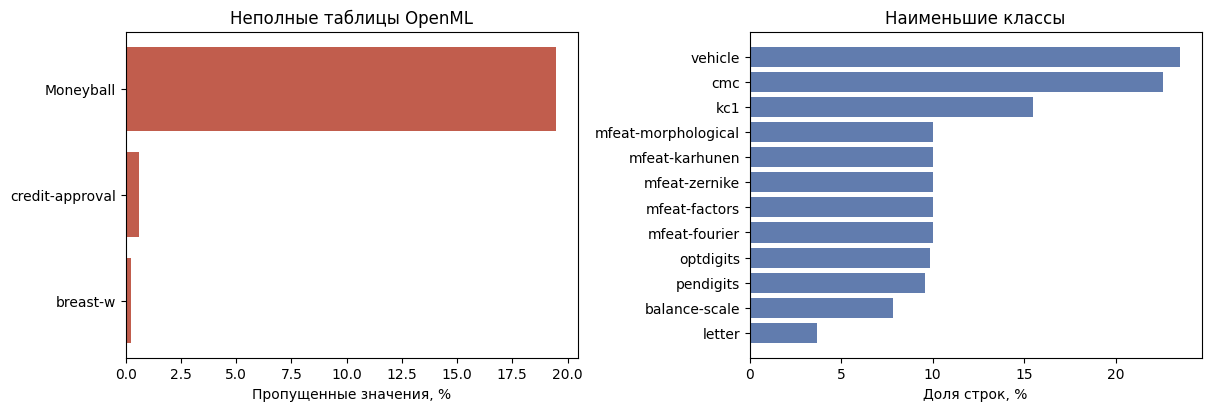

,name,rows,missing_percent
12,breast-w,699.0,0.228898
18,credit-approval,690.0,0.606884
24,Moneyball,1232.0,19.480519


In [3]:
missing = tabular[tabular.missing_percent > 0].sort_values("missing_percent")
minority = tabular[tabular.problem == "classification"].sort_values("minority_percent").head(12)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].barh(missing.name, missing.missing_percent, color="#c15d4d")
axes[0].set(title="Неполные таблицы OpenML", xlabel="Пропущенные значения, %")
axes[1].barh(minority.name, minority.minority_percent, color="#617cae")
axes[1].set(title="Наименьшие классы", xlabel="Доля строк, %")
fig.savefig(ASSETS / "data_quality.png", dpi=160)
plt.show()
display(missing[["name", "rows", "missing_percent"]])

## Сырые таблицы OpenML

Для `credit-g` проверяем классы, для `Moneyball` — числовую цель и пропуски признаков. Сырые строки не сохраняются в репозитории.

credit-g строк: 1000 признаков: 20 пропусков признаков: 0 пропусков цели: 0
Moneyball строк: 1232 признаков: 14 пропусков признаков: 3600 пропусков цели: 0


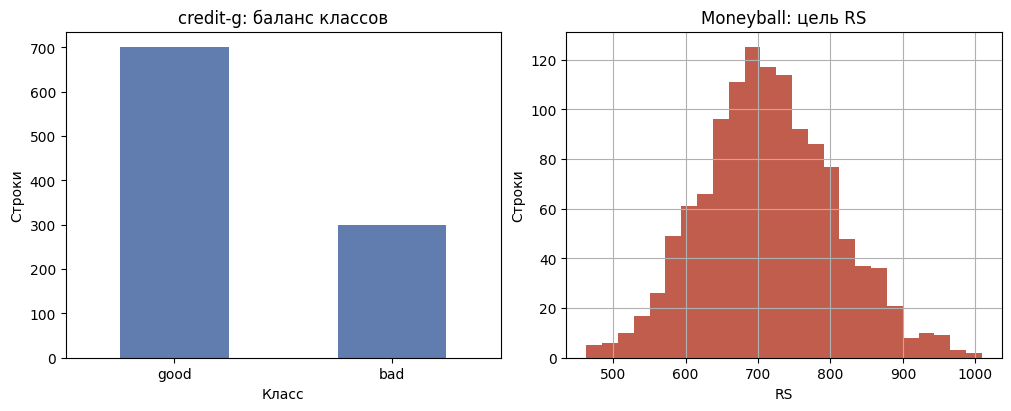

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
samples = []
for data_id, ax in [(31, axes[0]), (41021, axes[1])]:
    dataset = openml.datasets.get_dataset(data_id, download_data=True)
    X, y, _, _ = dataset.get_data(target=dataset.default_target_attribute, dataset_format="dataframe")
    print(dataset.name, "строк:", len(X), "признаков:", X.shape[1], "пропусков признаков:", int(X.isna().sum().sum()), "пропусков цели:", int(pd.isna(y).sum()))
    record = dict(openml_data=data_id, name=dataset.name, rows=len(X),
                  input_features=X.shape[1], missing_input_cells=int(X.isna().sum().sum()),
                  missing_target_rows=int(pd.isna(y).sum()))
    if data_id == 31:
        counts = pd.Series(y).value_counts()
        record["class_counts"] = {str(k): int(v) for k, v in counts.items()}
        counts.plot.bar(ax=ax, color="#617cae")
        ax.set(title="credit-g: баланс классов", xlabel="Класс", ylabel="Строки")
        ax.tick_params(axis="x", rotation=0)
    else:
        numeric = pd.to_numeric(y, errors="coerce")
        record["target_quantiles"] = {str(k): float(v) for k, v in numeric.quantile([0, .25, .5, .75, 1]).items()}
        numeric.hist(ax=ax, bins=25, color="#c15d4d")
        ax.set(title="Moneyball: цель RS", xlabel="RS", ylabel="Строки")
    samples.append(record)
(ASSETS / "raw_samples.json").write_text(json.dumps(samples, ensure_ascii=False, indent=2) + "\n")
fig.savefig(ASSETS / "raw_samples.png", dpi=160)
plt.show()

## Проверка всех таблиц и разбиений OpenML

Для каждой задачи использовано официальное `repeat=0, fold=0`. Считаем пропуски цели и признаков, повторы строк признаков и число строк test, чьи признаки точно совпадают со строкой train. Совпадение признаков у двух наблюдений не доказывает утечку цели.

,task_id,missing_input_cells,missing_target_rows,duplicate_feature_rows,test_rows_seen_in_train
0,openml-31-credit-g,0,0,0,0
1,openml-10101-blood-transfusion,0,0,246,25
2,openml-37-diabetes,0,0,0,0
3,openml-3917-kc1,0,0,917,106
4,openml-53-vehicle,0,0,0,0
5,openml-9952-phoneme,0,0,9,3
6,openml-3-kr-vs-kp,0,0,0,0
7,openml-146818-australian,0,0,0,0
8,openml-6-letter,0,0,1332,201
9,openml-11-balance-scale,0,0,0,0


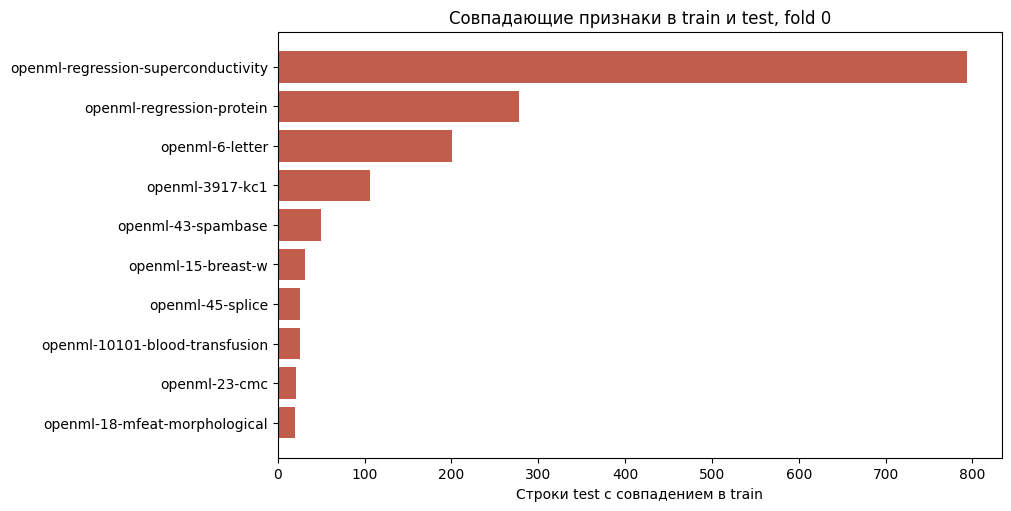

In [5]:
def audit_task(spec):
    task = openml.tasks.get_task(spec["openml_task"])
    dataset = task.get_dataset()
    features, target, _, _ = dataset.get_data(target=task.target_name, dataset_format="dataframe")
    train, test = task.get_train_test_split_indices(repeat=0, fold=0)
    fingerprints = pd.util.hash_pandas_object(
        features.astype("string").fillna("<missing>"), index=False)
    row = dict(task_id=spec["task_id"], openml_task=spec["openml_task"],
               openml_data=spec["openml_data"], problem=spec["problem"],
               rows=len(features), input_features=features.shape[1],
               missing_input_cells=int(features.isna().sum().sum()),
               rows_with_missing_input=int(features.isna().any(axis=1).sum()),
               missing_target_rows=int(pd.isna(target).sum()),
               duplicate_feature_rows=int(features.duplicated().sum()),
               train_rows=len(train), test_rows=len(test),
               test_rows_seen_in_train=int(fingerprints.iloc[test].isin(set(fingerprints.iloc[train])).sum()),
               target_unique=int(pd.Series(target).nunique(dropna=True)))
    if spec["problem"] == "classification":
        counts = pd.Series(target).value_counts(dropna=True)
        row["smallest_class_share_percent"] = round(100 * counts.min() / counts.sum(), 3)
    else:
        numeric = pd.to_numeric(target, errors="coerce")
        row.update(target_min=float(numeric.min()), target_median=float(numeric.median()),
                   target_max=float(numeric.max()))
    return row

audit = pd.DataFrame([audit_task(spec) for spec in registry["datasets"]
                      if spec["source"] == "openml_task"])
assert len(audit) == 32
audit.to_csv(ASSETS / "raw_audit.csv", index=False)
display(audit[["task_id", "missing_input_cells", "missing_target_rows",
               "duplicate_feature_rows", "test_rows_seen_in_train"]])
top = audit.nlargest(10, "test_rows_seen_in_train").sort_values("test_rows_seen_in_train")
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.barh(top.task_id, top.test_rows_seen_in_train, color="#c15d4d")
ax.set(title="Совпадающие признаки в train и test, fold 0", xlabel="Строки test с совпадением в train")
fig.savefig(ASSETS / "raw_audit.png", dpi=160)
plt.show()


В трёх задачах есть пропуски признаков; пропусков цели нет. В 17 задачах встречаются одинаковые строки признаков по обе стороны разбиения. Больше всего таких строк test в `Superconductivity` (794), `Physicochemical Protein` (278) и `letter` (201). Для оценки патча нужен отдельный разбор влияния этих повторов на метрику.

## Восемь временных рядов

Читаем выбранные целевые столбцы. Контрольные суммы защищают от смены CSV. Красный хвост оставлен для прогноза.

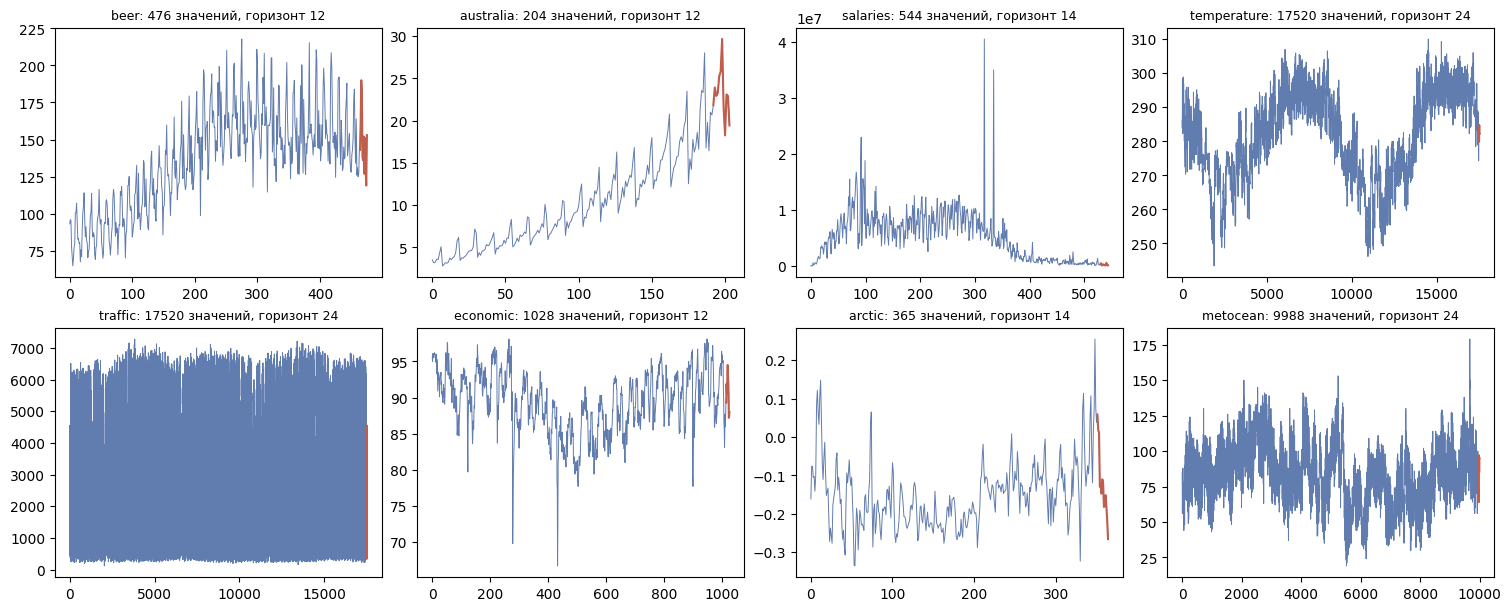

,ряд,строки,пропуски цели,горизонт
0,beer,476,0,12
1,australia,204,0,12
2,salaries,544,0,14
3,temperature,17520,0,24
4,traffic,17520,0,24
5,economic,1028,0,12
6,arctic,365,0,14
7,metocean,9988,0,24


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), constrained_layout=True)
summary = []
for ax, task in zip(axes.flat, [x for x in registry["datasets"] if x["problem"] == "ts_forecasting"]):
    path = (FEDOT / "examples/data/ts" / f"{task['ts_dataset']}.csv") if task["source"] == "fedot_public_ts" else (FEDOT / "examples/real_cases/data" / task["data_path"])
    assert hashlib.sha256(path.read_bytes()).hexdigest() == task["data_sha256"]
    frame = pd.read_csv(path)
    if task["source"] == "fedot_local_ts":
        column = next((c for c in frame if str(c).lower() in {"datetime", "timestamp", "date", "time"}), None)
        if column is not None:
            stamp = frame[column].astype(str).str.strip().str.removesuffix(".0")
            if stamp.str.fullmatch(r"\d{9,10}").all():
                stamps = pd.to_datetime(stamp.str[:8], format="%Y%m%d") + pd.to_timedelta(pd.to_numeric(stamp.str[8:]), unit="h")
            else:
                stamps = pd.to_datetime(stamp)
            frame = frame.iloc[np.argsort(stamps.to_numpy(), kind="stable")]
    values = pd.to_numeric(frame[task.get("target") or "value"], errors="coerce")
    n_missing = int(values.isna().sum())
    values = values.dropna().to_numpy()
    h = task["forecast_horizon"]
    summary.append((task["name"], len(frame), n_missing, h))
    ax.plot(values, linewidth=.7, color="#617cae")
    ax.plot(np.arange(len(values)-h, len(values)), values[-h:], color="#c15d4d")
    ax.set_title(f"{task['name']}: {len(values)} значений, горизонт {h}", fontsize=9)
fig.savefig(ASSETS / "time_series.png", dpi=160)
plt.show()
display(pd.DataFrame(summary, columns=["ряд", "строки", "пропуски цели", "горизонт"]))

## Выводы и пределы

- В реестре 40 задач разных типов и размеров; один датасет не заменяет проверку на всём наборе.
- Три таблицы OpenML содержат пропуски по метаданным. В восьми целевых рядах пропусков нет.
- Ряды имеют тренды, колебания и всплески; их проверяют хронологическим holdout.
- Сырые строки проверены во всех 32 задачах OpenML; в 17 задачах совпадают признаки отдельных строк train и test. Качество разметки и содержательную утечку этот подсчёт не устанавливает.
- EDA не доказывает улучшение патча; для этого нужен парный эксперимент.

Подробные выводы и ссылки на источники — в [отчёте](eda.md).

## Отдельный датасет для обучения Scout

Сорок задач выше используются для проверки патчей. Для обучения поиска гипотез нужна другая единица данных: одна гипотеза на зафиксированной версии FEDOT с контекстом кода и трассой; результаты Verifier, Fixer, парного сравнения и ревью становятся последующими метками. Такой очищенный размеченный набор пока не собран. Поэтому здесь нет графика «успешности обучения агента»: его нельзя вычислить из реестра датасетов проверки. Правила формирования и EDA этого будущего набора описаны в [дизайн-документе](ml_system_design_doc.md).